# SAM-Guided Window vs Wall Segmentation (Colab)

This notebook improves window/wall segmentation by using **guided prompts**:

1) You define a **wall box** and a few **window points** (positive) + **non-window points** (negative).
2) SAM creates a **wall mask** and a **window hint mask**.
3) An automatic mask pass is filtered using those hints to produce **clean window instances**.

**Design goals:**
- Minimal interactivity (no fragile widgets)
- Prompts are just numbers (reproducible)
- Batch-friendly outputs (overlays + binary masks)

---

## Outputs
- `__overlay.png` (window/wall visualization)
- `__window_mask.png` (binary)
- `__wall_mask.png` (binary)
- `__window_hint.png` (debug)


In [1]:
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install opencv-python matplotlib pillow numpy

import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamPredictor

print("CUDA:", torch.cuda.is_available())


  Preparing metadata (setup.py) ... done
CUDA: True


In [2]:
import pathlib

CKPT = "sam_vit_b_01ec64.pth"
if not pathlib.Path(CKPT).exists():
    !wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

sam = sam_model_registry["vit_b"](checkpoint=CKPT)
sam.to("cuda" if torch.cuda.is_available() else "cpu")
predictor = SamPredictor(sam)

print("SAM ready")


SAM ready


Saving IRX_2927.JPG to IRX_2927.JPG


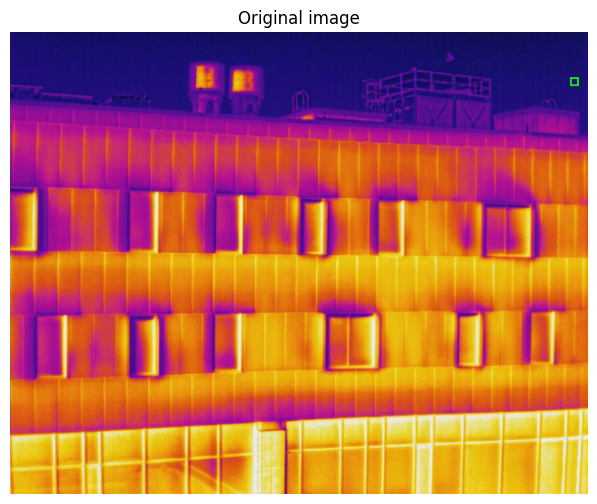

In [3]:
from google.colab import files

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

bgr = cv2.imread(img_path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8,6))
plt.imshow(rgb)
plt.title("Original image")
plt.axis("off")
plt.show()


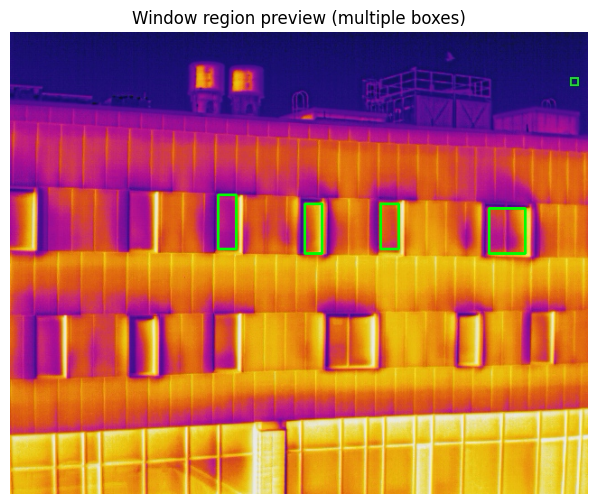

In [38]:
# Define MULTIPLE window regions (x0, y0, x1, y1)
WINDOW_BOXES = [
    [230, 180, 250, 240],
    [326, 190, 345, 245],
    [410, 190, 430, 240],
    [530, 195, 570, 245],
]

vis = rgb.copy()

for (x0, y0, x1, y1) in WINDOW_BOXES:
    cv2.rectangle(vis, (x0, y0), (x1, y1), (0, 255, 0), 2)

plt.figure(figsize=(8,6))
plt.imshow(vis)
plt.title("Window region preview (multiple boxes)")
plt.axis("off")
plt.show()


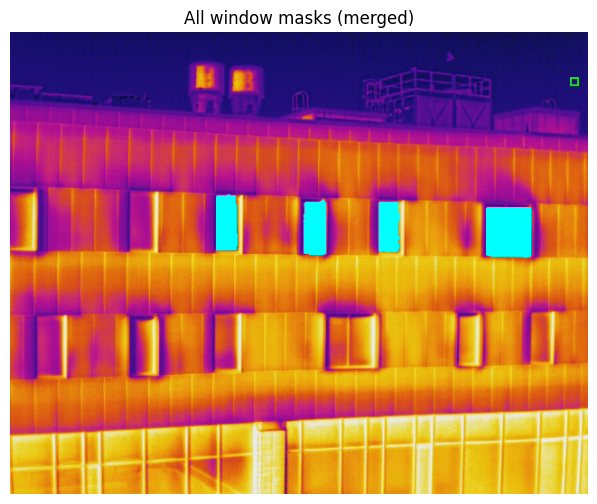

In [40]:
predictor.set_image(rgb)

H, W = rgb.shape[:2]
window_mask = np.zeros((H, W), dtype=bool)

for box in WINDOW_BOXES:
    box_np = np.array(box)[None, :]
    masks, scores, _ = predictor.predict(
        box=box_np,
        multimask_output=True
    )
    best = np.argmax(scores)
    window_mask |= masks[best]

overlay = rgb.copy()
overlay[window_mask] = [0, 255, 255]  # cyan windows

plt.figure(figsize=(8,6))
plt.imshow(overlay)
plt.title("All window masks (merged)")
plt.axis("off")
plt.show()


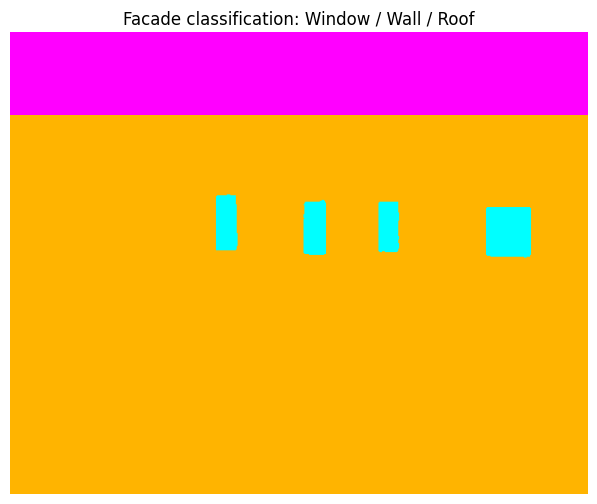

In [41]:
# =========================
# FULL FACADE CLASSIFICATION
# =========================

H, W = rgb.shape[:2]

# --- Roof definition (simple + robust) ---
ROOF_HEIGHT_RATIO = 0.18   # adjust if needed
roof_mask = np.zeros((H, W), dtype=bool)
roof_mask[:int(H * ROOF_HEIGHT_RATIO), :] = True

# --- Wall = everything else ---
wall_mask = (~window_mask) & (~roof_mask)

# --- Visualization ---
overlay = rgb.copy()
overlay[wall_mask]   = [255, 180, 0]   # wall (orange)
overlay[window_mask] = [0, 255, 255]   # window (cyan)
overlay[roof_mask]   = [255, 0, 255]   # roof (magenta)

plt.figure(figsize=(8,6))
plt.imshow(overlay)
plt.title("Facade classification: Window / Wall / Roof")
plt.axis("off")
plt.show()


In [42]:
window_area = window_mask.sum()
facade_area = (~roof_mask).sum()

window_ratio = window_area / facade_area

print(f"Window area ratio (of facade): {window_ratio:.3f}")


Window area ratio (of facade): 0.026


In [43]:
ious = []

for box in WINDOW_BOXES:
    x0, y0, x1, y1 = box
    box_mask = np.zeros((H, W), dtype=bool)
    box_mask[y0:y1, x0:x1] = True

    intersection = (window_mask & box_mask).sum()
    union = (window_mask | box_mask).sum()
    iou = intersection / max(union, 1)
    ious.append(iou)

print(f"Mean box–mask IoU: {np.mean(ious):.3f}")
print(f"Per-window IoU: {[round(i,3) for i in ious]}")


Mean box–mask IoU: 0.191
Per-window IoU: [np.float64(0.172), np.float64(0.152), np.float64(0.146), np.float64(0.292)]


In [1]:
# =========================
# 0) SETUP (RUN THIS CELL)
# =========================
!pip -q install git+https://github.com/facebookresearch/segment-anything.git
!pip -q install opencv-python matplotlib pillow tqdm scikit-image numpy

import torch
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

import pathlib
CHECKPOINT_DIR = pathlib.Path("checkpoints")
CHECKPOINT_DIR.mkdir(exist_ok=True)

SAM_MODEL_TYPE = "vit_b"  # vit_b is most stable on Colab
SAM_CKPT = CHECKPOINT_DIR / "sam_vit_b_01ec64.pth"

if not SAM_CKPT.exists():
    !wget -q -O checkpoints/sam_vit_b_01ec64.pth \
      https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

print("Checkpoint ready:", SAM_CKPT.exists(), str(SAM_CKPT))


  Preparing metadata (setup.py) ... done
PyTorch: 2.9.0+cpu
CUDA available: False
Checkpoint ready: True checkpoints/sam_vit_b_01ec64.pth


---
## 1) Imports + Model Load


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm

import torch
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor

np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"

sam = sam_model_registry[SAM_MODEL_TYPE](checkpoint=str(SAM_CKPT))
sam.to(device=device)

predictor = SamPredictor(sam)

mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,
    pred_iou_thresh=0.90,
    stability_score_thresh=0.92,
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=350
)

print("SAM loaded on:", device)


SAM loaded on: cpu


---
## 2) Configuration (Inputs/Outputs + Prompts)

### Prompts
- `WALL_BOX = [x0, y0, x1, y1]` rectangle that covers the façade wall region
- `WIN_POS_POINTS = [(x,y), ...]` points inside windows
- `WIN_NEG_POINTS = [(x,y), ...]` points on non-window (wall/sky/trees)

**Tip:** Use 5–12 positive points across multiple windows and 5–10 negative points.


In [8]:
# =========================
# INPUTS / OUTPUTS
# =========================


INPUT_IMAGE = "/content/drive/MyDrive/Research/112 RWH THERMAL OCT 5 2025/IRX_2925.JPG"   # optional single image for testing
INPUT_DIR   = "/content/drive/MyDrive/Research/112 RWH THERMAL OCT 5 2025"   # optional folder for batch (jpg/png/tif)

OUTPUT_DIR = "/content/seg_outputs_v3"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff"}

# =========================
# PROMPTS (EDIT THESE)
# =========================
WALL_BOX = None  # e.g. [40, 60, 1150, 760]
WIN_POS_POINTS = []  # e.g. [(200,150), (300,160), ...]
WIN_NEG_POINTS = []  # e.g. [(100,700), (900,740), ...]

# Controls
WINDOW_OVERLAP_THRESH = 0.20
WALL_COVER_THRESH     = 0.60
MIN_WINDOW_AREA_PX    = 400

print("OUTPUT_DIR:", OUTPUT_DIR)


OUTPUT_DIR: /content/seg_outputs_v3


---
## 3) Optional Coordinate Helper (Safe)

This is optional and intentionally simple: it shows the image so you can read pixel coordinates.


In [9]:
def show_image_for_coords(path):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(10,6))
    plt.imshow(rgb)
    plt.title("Read coordinates by hovering (x,y) in the plot toolbar")
    plt.axis("on")
    plt.show()


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## 4) Core Functions (Guided Masks + Filtering)


In [10]:
def _to_np_points(points):
    if not points:
        return None
    return np.array(points, dtype=np.float32)

def _mask_to_u8(mask_bool):
    return (mask_bool.astype(np.uint8) * 255)

def _overlay(image_bgr, wall_mask, window_mask, alpha=0.55):
    base = image_bgr.copy()
    overlay = base.copy()
    # BGR colors: wall=yellow, window=cyan
    if wall_mask is not None:
        overlay[wall_mask.astype(bool)] = (0, 255, 255)
    if window_mask is not None:
        overlay[window_mask.astype(bool)] = (255, 255, 0)
    blended = cv2.addWeighted(overlay, alpha, base, 1-alpha, 0)
    return cv2.cvtColor(blended, cv2.COLOR_BGR2RGB)

def sam_wall_mask(bgr, wall_box):
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    predictor.set_image(rgb)

    box = np.array(wall_box, dtype=np.float32)
    masks, scores, _ = predictor.predict(box=box[None, :], multimask_output=True)
    best = int(np.argmax(scores))
    return masks[best].astype(bool), float(scores[best])

def sam_window_hint_mask(bgr, pos_points, neg_points):
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    predictor.set_image(rgb)

    pos = _to_np_points(pos_points)
    neg = _to_np_points(neg_points)

    if pos is None or len(pos) == 0:
        raise ValueError("Provide at least one WIN_POS_POINTS point inside a window.")

    if neg is None:
        neg = np.zeros((0,2), dtype=np.float32)

    pts = np.vstack([pos, neg]).astype(np.float32)
    labels = np.array([1]*len(pos) + [0]*len(neg), dtype=np.int32)

    masks, scores, _ = predictor.predict(
        point_coords=pts,
        point_labels=labels,
        multimask_output=True
    )
    best = int(np.argmax(scores))
    return masks[best].astype(bool), float(scores[best])

def filter_window_instances(bgr, wall_mask, window_hint_mask):
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    auto_masks = sorted(mask_generator.generate(rgb), key=lambda x: x["area"], reverse=True)

    wall = wall_mask.astype(bool)
    hint = window_hint_mask.astype(bool)

    H, W = wall.shape
    win_merged = np.zeros((H, W), dtype=bool)
    selected = []

    for m in auto_masks:
        seg = m["segmentation"].astype(bool)
        area = int(seg.sum())
        if area < MIN_WINDOW_AREA_PX:
            continue

        inside = (seg & wall).sum() / max(1, area)
        if inside < WALL_COVER_THRESH:
            continue

        overlap = (seg & hint).sum() / max(1, area)
        if overlap < WINDOW_OVERLAP_THRESH:
            continue

        selected.append(seg)
        win_merged |= seg

    return win_merged, selected

def process_one(path, save=True, show=True):
    bgr = cv2.imread(str(path))
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {path}")

    if WALL_BOX is None:
        raise ValueError("Set WALL_BOX = [x0,y0,x1,y1] in the configuration cell.")

    wall_mask, wall_score = sam_wall_mask(bgr, WALL_BOX)
    hint_mask, hint_score = sam_window_hint_mask(bgr, WIN_POS_POINTS, WIN_NEG_POINTS)
    win_mask, instances = filter_window_instances(bgr, wall_mask, hint_mask)

    overlay_rgb = _overlay(bgr, wall_mask, win_mask, alpha=0.55)

    if save:
        stem = Path(path).stem
        cv2.imwrite(str(Path(OUTPUT_DIR)/f"{stem}__overlay.png"), cv2.cvtColor(overlay_rgb, cv2.COLOR_RGB2BGR))
        cv2.imwrite(str(Path(OUTPUT_DIR)/f"{stem}__wall_mask.png"), _mask_to_u8(wall_mask))
        cv2.imwrite(str(Path(OUTPUT_DIR)/f"{stem}__window_mask.png"), _mask_to_u8(win_mask))
        cv2.imwrite(str(Path(OUTPUT_DIR)/f"{stem}__window_hint.png"), _mask_to_u8(hint_mask))

    if show:
        plt.figure(figsize=(16,6))
        plt.subplot(1,4,1); plt.title("Original"); plt.axis("off")
        plt.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        plt.subplot(1,4,2); plt.title(f"Wall mask (score={wall_score:.3f})"); plt.axis("off")
        plt.imshow(wall_mask, cmap="gray")
        plt.subplot(1,4,3); plt.title(f"Window hint (score={hint_score:.3f})"); plt.axis("off")
        plt.imshow(hint_mask, cmap="gray")
        plt.subplot(1,4,4); plt.title(f"Final overlay (instances={len(instances)})"); plt.axis("off")
        plt.imshow(overlay_rgb)
        plt.tight_layout()
        plt.show()

    return {"wall_score": wall_score, "hint_score": hint_score, "n_instances": len(instances)}


---
## 5) Single Image Test


In [11]:
if INPUT_IMAGE.strip():
    stats = process_one(INPUT_IMAGE, save=True, show=True)
    print("Stats:", stats)
else:
    print("Set INPUT_IMAGE and prompts (WALL_BOX / points) first.")


ValueError: Set WALL_BOX = [x0,y0,x1,y1] in the configuration cell.

---
## 6) Batch Processing


In [ ]:
def list_images(folder):
    folder = Path(folder)
    return sorted([p for p in folder.rglob("*") if p.suffix.lower() in EXTS])

def batch_process(folder):
    paths = list_images(folder)
    if not paths:
        raise FileNotFoundError(f"No images found in: {folder}")
    print(f"Found {len(paths)} images. Processing...")

    summary = []
    for p in tqdm(paths):
        try:
            st = process_one(p, save=True, show=False)
            summary.append((p.name, st["wall_score"], st["hint_score"], st["n_instances"]))
        except Exception as e:
            print(f"[WARN] {p.name} failed: {e}")

    print("Done. Outputs saved to:", OUTPUT_DIR)
    if summary:
        print("\nSample summary (first 10):")
        for row in summary[:10]:
            print(row)

if INPUT_DIR.strip():
    batch_process(INPUT_DIR)
else:
    print("Set INPUT_DIR (and prompts) first.")


---
## 7) Tuning

- Too many false windows → increase `WINDOW_OVERLAP_THRESH` and/or `WALL_COVER_THRESH`, or raise `MIN_WINDOW_AREA_PX`.
- Missing windows → add more positive points; add negative points on walls; decrease `WINDOW_OVERLAP_THRESH`.
- Bad wall mask → tighten `WALL_BOX` to exclude sky/trees.
